# 03 — Audio pass: fetch, measure, discard

**Stage question.** Can every selected recording be read and measured, and what do its pitch and level look like, without ever storing the audio?

**Runtime.** Use a **CPU** Colab runtime (*Runtime → Change runtime type → CPU*). Nothing here needs a GPU, and GPU quota is kept for the neural stages.

| | |
|---|---|
| **Purpose** | For every interaction of the selected sessions: stream both participants' audio to the runtime's local disk, record a checksum, extract frame-level pitch and intensity tracks and channel-quality measures, then delete the audio. |
| **Input** | `manifests/coda_download_manifest.csv`; the transcripts and voice-activity files from notebook 02 (they must exist first). |
| **Processing** | Per interaction, in parallel workers: download → SHA-256 → read (48 kHz, 32-bit float, mono expected) → Praat pitch per voice-activity segment and Praat intensity over the file → quality measures → delete. Per session, results are written to Drive and a completion marker is set. |
| **Output** | `data/processed/audio_pass/<session>/` (tracks, per-file QC, fetch log, completion marker) and `data/processed/channel_qc.parquet` on Drive (git-ignored). `results/acquisition/audio_fetch_log.csv` (every audio file's size and checksum), `audio_pass_timing_<stage>.csv`, `selected_sessions_<stage>.csv`, run record. `figures/03_audio_pass/`. |
| **Scientific assumptions** | The released audio is the measurement object: peak-normalised per file and echo-suppressed upstream. Only within-file level differences are meaningful. Praat settings are the pinned values in `configs/features.yaml`. |
| **Failure modes** | A preempted Colab session (handled: finished sessions are skipped on rerun); a truncated download (detected against the server's declared size and retried); a file that changed upstream (detected later by checksum when the audio is re-fetched for self-supervised features). |
| **What to look at** | The timing table (it sets the budget for the full sample), the count of failed files, and the example interaction figure. |

**Terms used in this notebook.**

- **Sample rate / bit depth** — samples per second (48,000 here) and the numeric format of each sample (32-bit floating point here; the dataset card states 16-bit, which the files contradict).
- **Process-and-discard** — audio is kept only while it is being measured. Only the measurements are stored.
- **F0 (fundamental frequency)** — the vibration rate of the vocal folds, heard as pitch, in Hz. Measured with Praat's autocorrelation method.
- **Intensity** — Praat's energy contour in dB. Because each file is peak-normalised, intensity is compared within a file, never across files without the per-file offset.
- **Frame level (dBFS)** — the loudness of each 10 ms frame relative to digital full scale, used for quality control.
- **Echo suppression** — upstream processing that removes the partner's voice from each microphone. It can also reduce a speaker's own voice while both talk at once; notebook 04 measures this.
- **Checksum (SHA-256)** — a fingerprint of a file's bytes. The server does not version its files, so the checksum is what shows a later re-download is the same audio.

**Where pitch is measured, and why.** Two decisions shape this, and both are in `configs/features.yaml`.

*Per speech region, not per file.* Praat ignores frames quieter than 3% of the loudest point in the sound being analysed. In this corpus each file is scaled so its loudest point hits a fixed peak, and a single loud transient — a microphone bump, a clipped laugh — can then push ordinary speech below that 3% across the whole file. On one pilot file this cut voiced speech from 65% to 3.5%. Analysing each region of speech separately makes the reference point local to the speech being measured, which is how Praat is normally applied to speech units, and keeps every Praat setting at its default.

*Speech regions come from the voice-activity segments **and** the transcript.* The first pilot run defined those regions from the voice-activity detector alone, and gate G0 failed: turns of five seconds and longer were coming back with almost no pitch, because the detector had missed speech the transcript documented. At the largest recording site only 73% of word time falls inside detected speech on average, and 15% at the 5th percentile. Regions are now the union of both sources, merged where they overlap or lie within 50 ms. Taking a union can only widen the region analysed, never narrow it, and both sources ship with the corpus, so this is still a pure function of the audio and its metadata.

In [ ]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   13.0 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint e1a10dc2c7145664
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=53, channel_qc=True


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [ ]:
# Parameters
STAGE = 'sample'               # 'pilot': exactly the 40 pilot sessions, no replacement.
                              # 'sample': walk the ranked list until 250 sessions pass QC.
WORKERS = os.cpu_count() or 2 # parallel interactions; each holds two audio files on scratch disk
RUN_FROM_SCRATCH = False      # True: delete this stage's audio-pass outputs and redo them
MAX_SESSIONS_THIS_RUN = None  # e.g. 10 to process a batch per Colab session; None = all

In [ ]:
import json
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FeatureConfig
from src.paths import paths
from src.data.seamless import read_vad
from src.data.acquire import fetch_text_files, build_turn_tables
from src.features.tracks import Tracks
from src.preprocessing.audio_pass import (
    process_session, collect, load_tracks, done_variant
)
from src.preprocessing.channel_qc import usable_sessions
from src.runtime import write_run_record
from src.viz import style

# Rebuild the setup variables required by subsequent cells.
P = paths().ensure()
CFG = P.load_config('corpus')
style.apply()

ACQ = P.results / 'acquisition'
ACQ.mkdir(parents=True, exist_ok=True)

VARIANT = FeatureConfig().pitch_segment_source
FIGDIR = f'03_audio_pass__{STAGE}__{VARIANT}'

manifest = pd.read_csv(P.manifest, dtype=str)
manifest['selection_rank'] = manifest['selection_rank'].astype(int)

ranked = (
    manifest.drop_duplicates('session_key')
    .sort_values('selection_rank')
)

if STAGE == 'pilot':
    queue = ranked.loc[
        ranked['role'] == 'pilot', 'session_key'
    ].tolist()
    target = None
else:
    queue = ranked.loc[
        ranked['role'] != 'pilot', 'session_key'
    ].tolist()
    target = int(CFG['n_conversations'])

print(
    f"Stage {STAGE}: queue of {len(queue)} sessions"
    + (
        f", stopping once {target} pass channel QC"
        if target else ""
    )
)

Stage sample: queue of 684 sessions, stopping once 250 pass channel QC


## 1. Pre-flight checks

Transcripts and voice activity must already be on Drive (notebook 02), because pitch is measured per voice-activity segment and quality control splits frames by who is speaking. The scratch disk must hold two audio files per worker with room to spare.

In [ ]:
sizes_path = ACQ / 'remote_sizes_pilot.csv'
if sizes_path.exists():
    sizes = pd.read_csv(sizes_path)
    largest = sizes.loc[sizes['kind'] == 'audio', 'bytes'].max() / 1e9
else:
    largest = 0.4   # largest pilot file measured in notebook 01 was under 0.4 GB
need = 2 * largest * WORKERS
free = shutil.disk_usage(P.audio_scratch).free / 1e9
print(f"scratch disk free {free:.1f} GB; worst case in use at once {need:.1f} GB "
      f"({WORKERS} workers x 2 files x {largest:.2f} GB)")
assert free > 2 * need, 'Not enough scratch disk for this many workers; lower WORKERS.'

stage_rows = manifest[manifest['session_key'].isin(queue[: (target or len(queue))])]
missing_text = [f for f in stage_rows['file_id']
                if not (P.raw_transcript / f'{f}.jsonl').exists() or not (P.raw_vad / f'{f}.jsonl').exists()]
print(f"participant files without transcript or VAD on Drive: {len(missing_text)}")
if STAGE == 'pilot':
    assert not missing_text, 'Run notebook 02 for this stage first.'

scratch disk free 93.4 GB; worst case in use at once 1.5 GB (2 workers x 2 files x 0.39 GB)
participant files without transcript or VAD on Drive: 5438


In [ ]:
if RUN_FROM_SCRATCH:
    for sk in queue:
        shutil.rmtree(P.audio_pass / sk, ignore_errors=True)
    print('removed existing audio-pass outputs for this stage')

## 2. The pass

Sessions are processed in selection order. A session whose completion marker exists is skipped, so after a disconnection simply run this cell again. For the full sample, a session with no usable interaction is replaced by the next one in the ranked order — the preregistered random selection among sessions that pass quality control.

In [ ]:
timing_path = ACQ / f'audio_pass_timing_{STAGE}.csv'
timing = pd.read_csv(timing_path) if timing_path.exists() else pd.DataFrame()
selected, done_now = [], 0

for sk in queue:
    if target and len(selected) >= target:
        break
    rows_sk = manifest[manifest['session_key'] == sk]
    if not all((P.raw_vad / f'{f}.jsonl').exists() for f in rows_sk['file_id']):
        fetch_text_files(rows_sk, P)          # replacement sessions from the reserve
    marker = P.audio_pass / sk / 'DONE.json'
    already = marker.exists() and done_variant(marker) == VARIANT
    if not already and MAX_SESSIONS_THIS_RUN is not None and done_now >= MAX_SESSIONS_THIS_RUN:
        print('batch limit reached; rerun this cell to continue')
        break
    t0 = time.time()
    status = process_session(rows_sk, P, CFG, workers=WORKERS)
    secs = time.time() - t0
    qc_sk = pd.read_csv(P.audio_pass / sk / 'channel_qc.csv')
    ok = bool(usable_sessions(qc_sk).get(sk, False))
    if ok:
        selected.append(sk)
    if status == 'done':
        done_now += 1
        audio_s = qc_sk['duration_s'].fillna(0).sum()
        timing = pd.concat([timing, pd.DataFrame([{
            'session_key': sk, 'interactions': rows_sk['interaction_key'].nunique(),
            'audio_hours': audio_s / 3600, 'wall_seconds': secs, 'workers': WORKERS,
            'runtime': 'colab' if IN_COLAB else 'local'}])], ignore_index=True)
        timing.to_csv(timing_path, index=False)
    print(f"{sk:<12} {status:<8} usable={ok!s:<5} {secs:6.1f}s   usable so far {len(selected)}")

V01_S0134    skipped  usable=True     0.0s   usable so far 1
V03_S0331    skipped  usable=True     0.0s   usable so far 2
V03_S0706    skipped  usable=True     0.0s   usable so far 3
V00_S0768    skipped  usable=True     0.0s   usable so far 4
V01_S0138    skipped  usable=True     0.0s   usable so far 5
V03_S1103    skipped  usable=True     0.0s   usable so far 6
V02_S3456    skipped  usable=True     0.0s   usable so far 7
V02_S5703    skipped  usable=True     0.0s   usable so far 8
V02_S5127    skipped  usable=True     0.0s   usable so far 9
V00_S0051    skipped  usable=True     0.0s   usable so far 10
V03_S1168    skipped  usable=True     0.0s   usable so far 11
V03_S0868    skipped  usable=True     0.0s   usable so far 12
V00_S0579    skipped  usable=True     0.0s   usable so far 13
V03_S0507    done     usable=True    10.5s   usable so far 14
V02_S5233    done     usable=True    81.8s   usable so far 15
V03_S0082    done     usable=True    70.2s   usable so far 16
V03_S1766    done

## 3. Collect the outputs

Per-session results are combined into one table of channels. The fetch log — every audio file's size and checksum — is written to `results/`, where it is tracked: it is the evidence of exactly which bytes were measured.

In [ ]:
qc, flog = collect(P)
qc.to_parquet(P.processed / 'channel_qc.parquet', index=False)
flog = flog.drop(columns=['path'], errors='ignore')
flog.to_csv(ACQ / 'audio_fetch_log.csv', index=False)

ranks = ranked.set_index('session_key')['selection_rank']
done_now_set = [s for s in queue
                if (P.audio_pass / s / 'DONE.json').exists()
                and done_variant(P.audio_pass / s / 'DONE.json') == VARIANT]
sel = pd.DataFrame({'session_key': done_now_set})
sel['selection_rank'] = sel['session_key'].map(ranks)
sel['usable'] = sel['session_key'].map(usable_sessions(qc)).fillna(False)
sel = sel.sort_values('selection_rank').reset_index(drop=True)

selection_path = ACQ / f'selected_sessions_{STAGE}.csv'
if STAGE == 'sample':
    # The final manifest must contain exactly the first target usable NON-PILOT sessions.
    final_sel = sel.loc[sel['usable']].head(target).copy()
    if len(final_sel) < target:
        progress_path = ACQ / 'selected_sessions_sample_progress.csv'
        final_sel.to_csv(progress_path, index=False)
        # Do not leave a stale manifest that would let Notebook 07 run on an incomplete sample.
        selection_path.unlink(missing_ok=True)
        raise RuntimeError(
            f"Sample not ready: {len(final_sel)}/{target} usable non-pilot sessions completed. "
            "Rerun the audio-pass cell to continue; do not run Notebook 07 yet. "
            f"Progress saved to {progress_path.name}."
        )
    sel = final_sel
else:
    # Preserve every completed pilot session, including QC failures, for the G0 audit.
    pass

sel.to_csv(selection_path, index=False)
stage_qc = qc[qc['session_key'].isin(sel['session_key'])]
print(f"sessions in stage manifest {len(sel)}; usable {int(sel['usable'].sum())}")
print(f"channels {len(stage_qc)}; with an objective failure {int(stage_qc['failure'].notna().sum())}")
display(stage_qc['failure'].fillna('none').value_counts().to_frame('channels'))
display(flog['status'].value_counts().to_frame('audio files'))


sessions in stage manifest 250; usable 250
channels 5764; with an objective failure 164


,channels
failure,
none,5600
no_vad_speech,136
too_short_for_intensity,26
no_timed_words,2


,audio files
status,
fetched,6744


In [ ]:
if not timing.empty:
    t = timing.copy()
    rate = t['audio_hours'].sum() / (t['wall_seconds'].sum() / 3600)
    print(f"processed {t['audio_hours'].sum():.1f} h of audio in {t['wall_seconds'].sum() / 3600:.2f} h "
          f"wall time: {rate:.0f} h of audio per hour with {int(t['workers'].iloc[-1])} workers")
    per_session_h = t['wall_seconds'].median() / 3600
    print(f"median wall time per session {per_session_h * 60:.1f} min -> "
          f"about {per_session_h * 250:.1f} h for 250 sessions at this rate")

processed 324.5 h of audio in 3.93 h wall time: 83 h of audio per hour with 2 workers
median wall time per session 0.9 min -> about 3.8 h for 250 sessions at this rate


**Reading the timing.** The rate includes download, checksum, measurement and deletion. It is the measured budget for the full sample (the specification's compute plan gives only an estimate). Run the full sample in batches with `MAX_SESSIONS_THIS_RUN` if a single Colab session cannot hold it.

## 4. The subsample gets a turn table if sessions were replaced

For the full sample, replacements from the reserve were not in the turn tables built by notebook 02. They are rebuilt here over exactly the sessions that were processed, so every later stage sees one consistent set.

In [ ]:
built_for = json.loads((P.processed / 'turns_stage.json').read_text())['stage'] \
    if (P.processed / 'turns_stage.json').exists() else None
turn_sessions = set(pd.read_parquet(P.processed / 'turns.parquet', columns=['session_key'])['session_key']) \
    if (P.processed / 'turns.parquet').exists() else set()
if set(sel['session_key']) - turn_sessions:
    rows_sel = manifest[manifest['session_key'].isin(sel['session_key'])]
    turns, pairs, stats = build_turn_tables(rows_sel, P)
    turns.to_parquet(P.processed / 'turns.parquet', index=False)
    pairs.to_parquet(P.processed / 'pairs_candidates.parquet', index=False)
    stats.to_parquet(P.processed / 'transcript_stats.parquet', index=False)
    (P.processed / 'turns_stage.json').write_text(json.dumps({'stage': STAGE, 'rebuilt_after_audio_pass': True}))
    print(f"turn tables rebuilt over {len(sel)} processed sessions")
else:
    print('turn tables already cover every processed session')

/content/drive/MyDrive/coda/src/data/turns.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  allu = pd.concat(units, ignore_index=True)
/content/drive/MyDrive/coda/src/data/turns.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  allu = pd.concat(units, ignore_index=True)
/content/drive/MyDrive/coda/src/data/turns.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns 

turn tables rebuilt over 250 processed sessions


## 5. One interaction, looked at directly

Thirty seconds of one interaction: the two microphones' frame levels, the detected speech of each speaker, and the pitch track of each. This is a sanity check of the measurement, not evidence for any hypothesis.

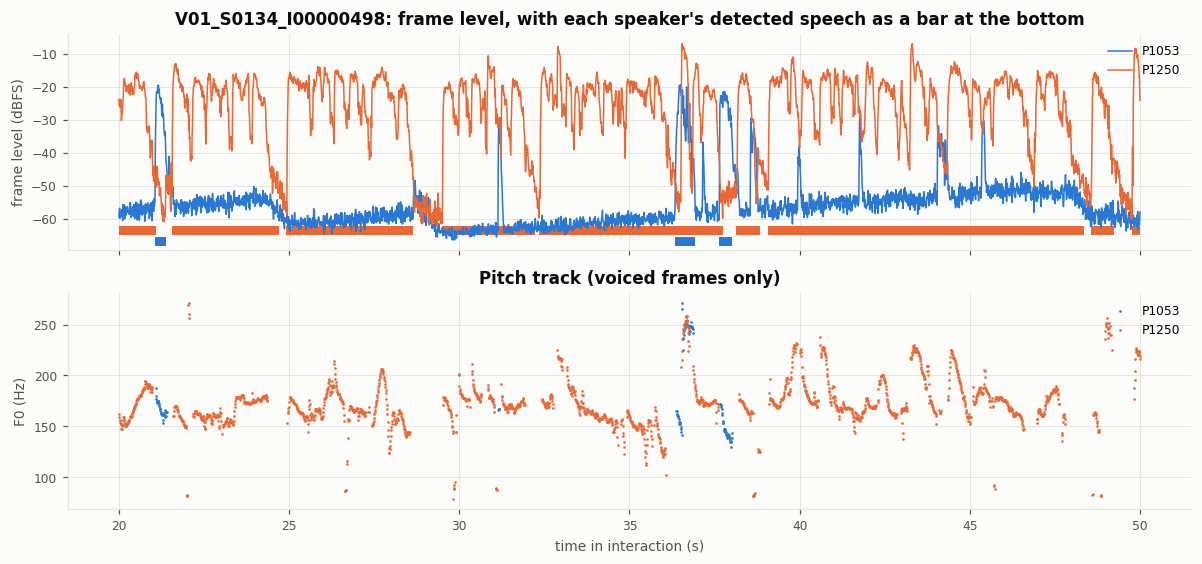

In [ ]:
sk = sel.loc[sel['usable'], 'session_key'].iloc[0]
q = stage_qc[(stage_qc['session_key'] == sk) & stage_qc['failure'].isna()]
ik = q.groupby('interaction_key')['overlap_s'].sum().idxmax()     # the one with most overlap
fids = sorted(q.loc[q['interaction_key'] == ik, 'file_id'])
npz = load_tracks(P, sk)
T0, T1 = 20.0, 50.0

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for i, fid in enumerate(fids):
    tr = Tracks.from_npz(npz, fid)
    t_lv = (np.arange(tr.frame_dbfs.size) + 0.5) * tr.step_s
    m = (t_lv >= T0) & (t_lv < T1)
    who = fid.rsplit('_P', 1)[1]
    axes[0].plot(t_lv[m], tr.frame_dbfs[m], color=style.SERIES[i], linewidth=1.0, label=f'P{who}')
    for s, e in read_vad(P.raw_vad / f'{fid}.jsonl').itertuples(index=False):
        if e > T0 and s < T1:
            axes[0].axvspan(max(s, T0), min(e, T1), ymin=0.02 + 0.05 * i, ymax=0.06 + 0.05 * i,
                            color=style.SERIES[i])
    t_f0 = tr.f0_t0 + np.arange(tr.f0_hz.size) * tr.step_s
    m = (t_f0 >= T0) & (t_f0 < T1) & (tr.f0_hz > 0)
    axes[1].scatter(t_f0[m], tr.f0_hz[m], s=3, color=style.SERIES[i], label=f'P{who}')
axes[0].set_ylabel('frame level (dBFS)')
axes[0].set_title(f'{ik}: frame level, with each speaker\'s detected speech as a bar at the bottom')
axes[0].legend(loc='upper right')
axes[1].set_ylabel('F0 (Hz)')
axes[1].set_xlabel('time in interaction (s)')
axes[1].set_title('Pitch track (voiced frames only)')
axes[1].legend(loc='upper right')
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'example_interaction')
plt.show()

**What is plotted.** Top: the 10 ms frame level of each participant's microphone, with each speaker's detected speech drawn as a coloured bar along the bottom. Bottom: the pitch track of each speaker, voiced frames only. The interaction shown is the one in its session with the most overlapping speech, the hardest case for echo suppression.

**Why it matters.** It shows directly whether each channel carries one speaker: level should rise on a channel when its own speaker talks and stay near the floor when only the partner talks. Where both speak, both channels should carry speech; a channel dropping to the floor while its speaker is detected as talking is the echo-suppression gating that would create silences that are not pauses.

**What would indicate a problem.** One channel echoing the other's level pattern (bleed); a channel going silent during its own detected speech (gating); pitch tracks at implausible values for one speaker (octave errors); pitch points outside detected speech (there should be none, by construction).

**Conclusion.** A single interaction proves nothing about the corpus. The corpus-wide versions of these checks are the distributions in notebook 04, which decide gate G0.

In [ ]:
rec = write_run_record(ACQ / f'03_run_record_{STAGE}.json', '03_audio_pass', {
    'stage': STAGE, 'workers': WORKERS,
    'praat': {k: v for k, v in FeatureConfig().__dict__.items()
              if k.startswith(('f0_', 'frame_', 'max_', 'very_', 'silence', 'voicing', 'octave',
                               'voiced_', 'intensity'))},
    'pitch_segment_source': VARIANT,
    'pitch_analysis': 'per speech region, padded by 3 / f0_floor_hz',
    'sessions_processed': int(len(sel)), 'sessions_usable': int(sel['usable'].sum()),
    'channels': int(len(stage_qc)), 'channels_failed': int(stage_qc['failure'].notna().sum()),
    'audio_bytes_measured': int(flog['bytes'].sum()),
})
print('run record written')

run record written


## Summary

- Every selected interaction's audio was streamed, fingerprinted, measured and deleted; no audio remains on any disk, and none reached Drive.
- Frame-level pitch and intensity tracks and channel-quality measures are stored per session, so every later measurement is computed from them without another download.
- The measured processing rate replaces the specification's estimate as the budget for the full sample.

**What this stage does not establish.** Whether the channels are good enough to measure delivery. That judgement, against the specification's thresholds, is gate G0 in the next notebook.

**Next.** `04_audit`.